In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

## **Postprocess Data**

In [ ]:
technologies_df = visualisation.load_df("../data/visualisation_files/df_technologies_cost.parquet")
def dicts_to_tuples(units):
    return [(u.get('text', ''), u.get('exponent', None), u.get('unit_uri', ''), u.get('year', None)) 
            for u in units]

technologies_df['unit_normalized'] = technologies_df['unit_normalized'].apply(dicts_to_tuples)

In [ ]:
technologies_df["property"].value_counts()

In [ ]:
print(technologies_df["unit_normalized"].value_counts())
print("--------------------------------------------------------------------------------")
exclude_values = [
    [(None, None, 'http://qudt.org/vocab/unit/UNITLESS', None)],
    [('%', 1.0, 'http://qudt.org/vocab/unit/PERCENT', None)],
    [(None, None, 'http://qudt.org/vocab/unit/UNITLESS', None)]   
]
technologies_df = technologies_df[~technologies_df["unit_normalized"].isin(exclude_values)]
print(technologies_df["unit_normalized"].value_counts())

In [ ]:
#target_unit = [("GW", 1.0, "http://qudt.org/vocab/unit/MegaW", None)]
target_unit = [("$", 1.0, "http://qudt.org/vocab/currency/USD", None), ("kg", -1.0, "http://qudt.org/vocab/unit/KiloGM", None)]
technologies_df['value_converted'] = technologies_df.apply(visualisation.convert_row, axis=1, args=(target_unit,))

In [ ]:
technologies_df = technologies_df[technologies_df["value_converted"].notna()]
technologies_df = technologies_df.reset_index(drop=True)
technologies_df.to_parquet("../data/visualisation_files/unit_converted/df_technologies_capacity_usd_kg.parquet")

## **Visualise Results**

In [ ]:
farbe_hydrogen = {
    'Hydrogen': '#000000',            # black
    'Blue': '#0072B2',       # blue
    'Grey': '#999999',       # gray
    'Yellow': '#E69F00',     # orange (statt gelb)
    'Green': '#009E73',      # green
}

### **Levelized Cost**

In [ ]:
cost_kg = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_cost_usd_kg.xlsx")
cost_kwh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_cost_usd_kwh.xlsx")

In [ ]:
fig = visualisation.plot_top_values(cost_kg, column="entity_mapping", top_n=20, ignore_empty=True, figsize=(6,6), title="Top 20 Entities")

#### Select Entities

In [ ]:
# ---------------------------------------- ENTITY BASE MAPPING -----------------------------------

# cost_kg = cost_kg[cost_kg["entity_base_mapping"].isin(['hydrogen'])]
cost_kwh = cost_kwh[cost_kwh["entity_base_mapping"].isin(['pv', 'wind turbine', 'natural gas'])]


# ---------------------------------------- ENTITY MAPPING -----------------------------------

# cost_kwh = cost_kwh[cost_kwh["entity_mapping"].isin(['Battery', 'Lithium-Ion Battery'])]
# cost_kwh["entity_mapping"] = cost_kwh["entity_mapping"].replace({
#     'Lithium-Ion Battery': 'Lithium Ion',
#     'Lead Acid Battery': 'Lead Acid',
#     'Nickel-Iron Battery': 'Nickel-Iron',
#     'Lithium Iron Phosphate Battery': 'Lithium Iron Phosphate',
# })

# cost_kwh = cost_kwh[cost_kwh["entity_mapping"].isin(['Wind Turbine', 'Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# cost_kwh["entity_mapping"] = cost_kwh["entity_mapping"].replace({
#     'Wind Turbine': 'Wind Turbine',
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore',
# })

# cost_kwh = cost_kwh[cost_kwh["entity_mapping"].isin(['PVSystem', 'Hybrid PV System', 'Utility-scale PV System'])]
# cost_kwh["entity_mapping"] = cost_kwh["entity_mapping"].replace({
#     'PVSystem': 'PV',
#     'Hybrid PV System': 'Hybrid',
#     'Utility-scale PV System': 'Utility-scale',
#     'Rooftop PV System': 'Rooftop',
#     'Photovoltaic-Thermal System (PVT)': 'PVT'
# })

cost_kg = cost_kg[cost_kg["entity_mapping"].isin(['Hydrogen', 'Green Hydrogen'])]
cost_kg["entity_mapping"] = cost_kg["entity_mapping"].replace({
    'Hydrogen': 'Hydrogen',
    'Blue Hydrogen': 'Blue',
    'Grey Hydrogen': 'Grey',
    'Yellow Hydrogen': 'Yellow',
    'Green Hydrogen': 'Green'
})

In [ ]:
data = [
    {
    'df': cost_kg,
    'entity_col': 'entity_mapping',
    'value_col': 'value_converted',
    'ylabel': 'Levelized Cost [USD/kWh]', 
    'palette': farbe_hydrogen,
    }
]

fig = visualisation.plot_multiple_properties_over_time(
    data_list=data,
    legend_title = 'Battery Type',
    figsize=(12,6),
    legend_position=(0.79,0.96),
    legend_size_position=(0.645,0.96),
    central_tendency="moving average",
    error_type="se",
    error_display="shade"
    )

fig.show()
#fig.savefig("../data/figures/results/level_cost/battery_cost.pdf")

### **Lifetime**

In [3]:
lifetime = pd.read_parquet("../data/visualisation_files/df_technologies_lifetime.parquet")
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]    801
[{'exponent': 1.0, 'text': 'year', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]      48
[{'exponent': 1.0, 'text': 'yr', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]         3
[{'exponent': 1.0, 'text': 'a', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]          2
[{'exponent': 1.0, 'text': 'yrs', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]        2
[{'exponent': 1.0, 'text': 'y', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]          1
Name: count, dtype: int64

#### Select Entities

In [4]:
lifetime = lifetime[lifetime["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

In [5]:
fig = visualisation.plot_properties_over_time(
    df = lifetime,
    entity_col = 'entity_base_mapping',
    value_col = 'value_normalized',
    ylabel = 'Lifetime [Years]', 
    title = 'Levelized Cost of Wind Turbine Over Time',
    legend_title = 'Technology Type',
    figsize=(14,6),
    legend_position=(0.81,0.49),
    legend_size_position=(0.685,0.49),
    central_tendency="moving average",
    #palette = farbe_hydrogen,
    error_type="se",
    error_display="shade"
    )

fig.show()
#fig.savefig("../data/figures/results/lifetime/technologies_lifetime.pdf", bbox_inches='tight')

AttributeError: 'QuinexVisualisation' object has no attribute 'plot_properties_over_time'

#### **Efficiency**

In [6]:
efficiency = pd.read_parquet("../data/visualisation_files/df_technologies_efficiency.parquet")
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          817
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]      3
Name: count, dtype: int64

#### Select Entities

In [7]:
efficiency = efficiency[efficiency["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_19860\3665941312.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


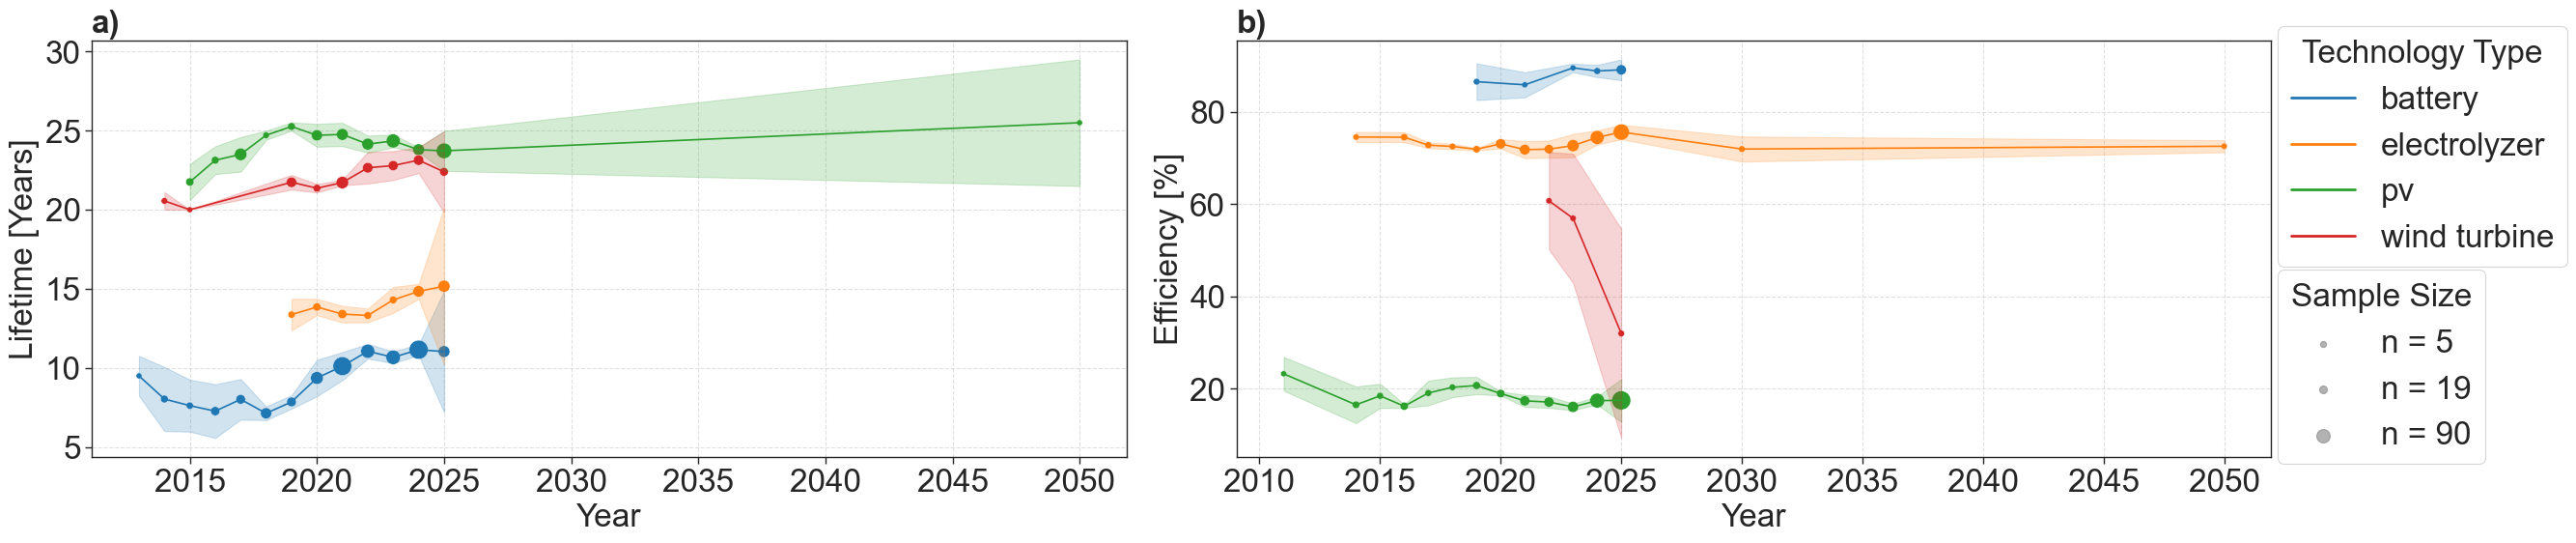

In [8]:
data = [
    {
    'df': lifetime,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]', 
    },
    {
    'df': efficiency,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    },
    # {
    # 'df': cost_kwh,
    # 'entity_col': 'entity_base_mapping',
    # 'value_col': 'value_converted',
    # 'ylabel': 'Levelized Cost [USD/kWh]', 
    # }
]


fig = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    figsize=(24,6),
    legend_position=(0.984,0.95),
    legend_size_position=(0.984,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=24
    )

fig.show()
fig.savefig("../data/figures/results/technologies_properties.pdf", bbox_inches='tight')

#### **Capacity**

In [ ]:
capacity = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capacity_mw.xlsx")

In [ ]:
fig = visualisation.plot_top_values(capacity, column="entity", top_n=20, ignore_empty=True, figsize=(6,6), title="Top 20 Entities")

#### Select Entities

In [ ]:
#capacity = capacity[capacity["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

#capacity = capacity[capacity["entity_mapping"].isin(['PVSystem', 'Wind Turbine'])]

# capacity = capacity[capacity["entity_mapping"].isin(['Offshore Wind Turbine', 'Floating Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# capacity["entity_mapping"] = capacity["entity_mapping"].replace({
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore'
# })

capacity = capacity[capacity["entity_mapping"].isin(['Hybrid PV System', 'Utility-scale PV System', 'Rooftop PV System', 'Photovoltaic-Thermal System (PVT)'])]
capacity["entity_mapping"] = capacity["entity_mapping"].replace({
    'Hybrid PV System': 'Hybrid PV',
    'Utility-scale PV System': 'Utility-scale PV',
    'Rooftop PV System': 'Rooftop PV',
    'Photovoltaic-Thermal System (PVT)': 'PVT'
})

capacity = capacity[capacity["property"].isin(['installed capacity'])]

In [ ]:
fig = visualisation.plot_properties_over_time(
    df = capacity,
    entity_col = 'entity_base_mapping',
    value_col = 'value_converted',
    ylabel = 'Installed Capacity [GW]', 
    title = 'Levelized Cost of Wind Turbine Over Time',
    legend_title = 'Technology Type',
    figsize=(12,6),
    legend_position=(0.075,0.965),
    legend_size_position=(0.265,0.965),
    central_tendency="moving average",
    #palette = farbe_hydrogen,
    error_type="se",
    error_display="shade"
    )

fig.show()
fig.savefig("../data/figures/results/capacity/technologies_capacity.pdf", bbox_inches='tight')